# Week 2 — Double Machine Learning, explained step by step

**EconoCausal: does sending an email change customer behaviour?**

This notebook trains EconML `CausalForestDML` with Random Forest base models, produces customer-profile effect estimates, and evaluates uplift rankings on held-out customers. It follows the supplied Week 2 requirements. The observed actions are **no email, men's merchandise email, and women's merchandise email**; there are no $10/$20 discount observations.

**Review verdict:** the previous notebook had the right DML estimator, categorical treatment, cross-fitting, and held-out evaluation. However, it depended on old helper files and old preprocessing outputs. This replacement uses notebook 02's engineered features, validates the split and feature matrix, explains the method, handles tied scores fairly, and includes uncertainty and Plotly exports.

### Before you start
1. Run `02_preprocessing_feature_engineering.ipynb` from this repository with **Run All**. The older `train.csv` and `test.csv` are not the inputs for this notebook.
2. Select the same project Python kernel in VS Code.
3. Run this notebook from top to bottom. Training three models can take several minutes.

Dependencies: numpy, pandas, scipy, scikit-learn, econml, matplotlib, plotly, joblib, ipykernel. The exact successfully tested package versions are printed below. If an import is missing, install that dependency in the selected notebook kernel with `%pip install package_name`, then restart the kernel. Do not reinstall packages when imports already work.

No hidden helper scripts are needed. Only this notebook is added to GitHub; running it creates model, score, and chart files locally.

## 1. The question, using a small example

Suppose customers like Asha have an 8% purchase chance without an email and 11% with an email. Their **estimated uplift is 11% − 8% = 3 percentage points**. Among 100 similar customers, that means about three additional purchases on average. These numbers are an illustration, not a result from this dataset.

A customer who would buy anyway may have a high buying probability but little uplift. We want the extra change caused by the action, not simply a high buying probability.

We never observe the same person both receiving and not receiving the same campaign. The model therefore estimates a **conditional average treatment effect (CATE)** for similar profiles, often called an “ITE score” in project dashboards. It cannot identify each person's true individual effect or prove who is a persuadable.

- `X`: information from before the campaign, including engineered features from notebook 02.
- `T`: `0 = no email`, `1 = men's email`, `2 = women's email`. These are categories, not discount sizes or a numeric dose.
- `Y`: `visit` (primary), `conversion` and `spend` (secondary). Visits are more common than purchases, which helps estimation.

Visit/conversion effects are probability differences; multiply by 100 for percentage points. Spend effects are additional dollars per customer, not profit.

In [1]:
from pathlib import Path
import json
import hashlib
import time
from importlib.metadata import version
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from econml.dml import CausalForestDML

SEED = 42
OUTCOMES = ["visit", "conversion", "spend"]
ARMS = {1: "mens", 2: "womens"}
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/raw/hillstrom.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open the repository containing data/raw/hillstrom.csv.")
OUTPUT = ROOT / "results/double_ml"
MODEL_DIR = ROOT / "models/double_ml"
OUTPUT.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
versions = {p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "econml", "matplotlib", "plotly", "joblib"]}
display(pd.Series(versions, name="Tested runtime version"))

/Users/sharath/economl_project-1/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


numpy            2.4.6
pandas           3.0.6
scipy           1.15.3
scikit-learn     1.9.1
econml          0.17.0
matplotlib      3.11.2
plotly           6.9.0
joblib           1.6.0
Name: Tested runtime version, dtype: str

## 2. Load and check notebook 02's prepared data

This is the original randomized sample, not the matched sample from notebook 04. Matching was a balance diagnostic and does not replace the randomized training data.

We check that IDs do not overlap, that the split matches the declared seed, that the encoder reproduces the saved features, and that treatment/outcomes did not enter X. Generated IDs identify source rows, not verified unique people. The raw dataset has no real customer identifier.

In [2]:
needed = ["data/processed/causal_train.csv", "data/processed/causal_test.csv",
          "data/processed/causal_clean.csv", "models/causal_preprocessor.joblib",
          "results/causal_preprocessing_summary.json"]
missing = [p for p in needed if not (ROOT / p).exists()]
if missing:
    raise FileNotFoundError("Run notebook 02 first. Missing: " + ", ".join(missing))
train = pd.read_csv(ROOT / needed[0])
test = pd.read_csv(ROOT / needed[1]).sort_values("customer_id").reset_index(drop=True)
clean = pd.read_csv(ROOT / needed[2])
# Load only the preprocessor created locally by your own notebook 02.
encoder = joblib.load(ROOT / needed[3])
preparation = json.loads((ROOT / needed[4]).read_text())
features = preparation["feature_columns_after_encoding"]
raw_features = preparation["feature_columns_before_encoding"]
forbidden = {"customer_id", "segment", "treatment", "treatment_name", *OUTCOMES}
assert not forbidden.intersection(features)
assert not forbidden.intersection(raw_features)
assert len(set(features)) == len(features)
assert list(encoder.get_feature_names_out()) == features
assert clean.customer_id.is_unique and train.customer_id.is_unique and test.customer_id.is_unique
assert set(train.customer_id).isdisjoint(test.customer_id)
assert set(train.customer_id) | set(test.customer_id) == set(clean.customer_id)
assert len(train) + len(test) == len(clean)
expected_train, expected_test = train_test_split(np.arange(len(clean)), test_size=0.30,
                                                random_state=SEED, stratify=clean.treatment)
assert set(train.customer_id) == set(clean.iloc[expected_train].customer_id)
assert set(test.customer_id) == set(clean.iloc[expected_test].customer_id)
lookup = clean.set_index("customer_id")
for frame in [train, test]:
    assert set(frame.treatment.unique()) == {0, 1, 2}
    aligned = lookup.loc[frame.customer_id]
    assert np.array_equal(frame[["treatment", *OUTCOMES]].to_numpy(), aligned[["treatment", *OUTCOMES]].to_numpy())
    assert np.allclose(frame[features].to_numpy(), encoder.transform(aligned[raw_features]))
    assert np.isfinite(frame[features + OUTCOMES].to_numpy()).all()
    assert frame[["visit", "conversion"]].isin([0, 1]).all().all()
    assert (frame.spend >= 0).all()
X_train = train[features].to_numpy(dtype=float)
X_test = test[features].to_numpy(dtype=float)
X_all = encoder.transform(clean[raw_features])
T_train = train.treatment.to_numpy()
print(f"Training: {len(train):,}; independent evaluation: {len(test):,}; features: {len(features)}")
print("Feature/split checks passed. No matched rows or held-out outcomes enter training.")
display(pd.crosstab(pd.concat([train.assign(split="train"), test.assign(split="test")])["split"],
                    pd.concat([train, test])["treatment"].to_numpy()))

Training: 44,800; independent evaluation: 19,200; features: 16
Feature/split checks passed. No matched rows or held-out outcomes enter training.


col_0,0,1,2
split,,,
test,6392,6392,6416
train,14914,14915,14971


## 3. What “Double ML” actually does

Think of two helpers and one final judge:

1. **Outcome helper** learns the typical outcome for each starting profile: `m(X) = E[Y | X]`. We use a Random Forest regressor. For 0/1 outcomes, predicting the conditional mean is a valid way to predict a probability; `discrete_outcome=False` is intentional.
2. **Treatment helper** learns assignment probabilities: `e(X) = P(T | X)`. It is a Random Forest classifier because the three actions are categories. Randomization means probabilities should be near one third; learning them satisfies the requested DML workflow but is not what establishes random assignment.
3. **Causal forest** connects the remaining outcome variation to the remaining treatment variation, allowing the effect to vary by profile.

In simple notation: `outcome residual = Y − m(X)` and `treatment residual = one_hot(T) − e(X)`. The forest learns how these residuals relate locally. EconML handles the multi-arm calculation and treats action 0 as the reference.

**Cross-fitting:** split training rows into three folds. Each helper predicts a fold using models trained on the other two. Thus a helper does not predict a training row using that row's outcome. The final holdout remains separate from all three folds.

**Honest forest:** tree split selection and within-leaf effect estimation use separate observations. Larger leaves reduce noisy estimates in this small-effect, rare-purchase setting. These preset settings are not tuned on the test set.

DML does not magically remove unmeasured confounders. Interpretation requires the study's randomization (or no unmeasured confounding), overlap, correctly recorded treatment/outcomes, and no interference between customers.

In [3]:
def make_model():
    outcome_helper = RandomForestRegressor(
        n_estimators=60, max_depth=10, min_samples_leaf=40,
        random_state=SEED, n_jobs=2)
    treatment_helper = RandomForestClassifier(
        n_estimators=60, max_depth=8, min_samples_leaf=80,
        random_state=SEED, n_jobs=2)
    return CausalForestDML(
        model_y=outcome_helper, model_t=treatment_helper,
        discrete_outcome=False, discrete_treatment=True, categories=[0, 1, 2],
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
        n_estimators=120, subforest_size=4, min_samples_leaf=120,
        max_depth=10, honest=True, inference=True,
        random_state=SEED, n_jobs=2)

models = {}
all_scores = clean[["customer_id", *raw_features, "treatment", *OUTCOMES]].copy()
all_scores["split"] = np.where(clean.customer_id.isin(train.customer_id), "train", "test")
test_scores = test[["customer_id", "treatment", *OUTCOMES]].copy()
test_scores["split"] = "test"
for outcome in OUTCOMES:
    started = time.time()
    print(f"Training {outcome}...", flush=True)
    model = make_model()
    model.fit(train[outcome].to_numpy(), T_train, X=X_train)
    models[outcome] = model
    for arm, name in ARMS.items():
        effect = model.effect(X_test, T0=0, T1=arm).ravel()
        low, high = model.effect_interval(X_test, T0=0, T1=arm, alpha=0.05)
        assert effect.shape == (len(test),) and np.isfinite(effect).all()
        assert np.isfinite(low).all() and np.isfinite(high).all()
        assert (low <= high).all()
        test_scores[f"{outcome}_{name}"] = effect
        test_scores[f"{outcome}_{name}_lower95"] = low.ravel()
        test_scores[f"{outcome}_{name}_upper95"] = high.ravel()
        all_scores[f"{outcome}_{name}"] = model.effect(X_all, T0=0, T1=arm).ravel()
    joblib.dump(model, MODEL_DIR / f"{outcome}_forest.joblib", compress=3)
    print(f"Finished {outcome} in {(time.time() - started):.1f} seconds.", flush=True)
print("All three models fitted on training rows only.")

Training visit...


Finished visit in 27.9 seconds.


Training conversion...


Finished conversion in 29.7 seconds.


Training spend...


Finished spend in 30.7 seconds.


All three models fitted on training rows only.


## 4. Read the effect scores and uncertainty correctly

`visit_mens = 0.04` means an estimated **4 percentage point increase in visits** from men's email versus no email for that profile. A negative score means an estimated reduction, not an error to delete. Estimates and intervals are not clipped to hide uncertainty.

The forest intervals describe approximate uncertainty in **profile-average** effects. They are pointwise, not simultaneous guarantees for thousands of customers. We also compare mean predicted effects with a simple held-out randomized difference in group means and its approximate 95% interval. The latter is a separate aggregate sanity check, not an ITE accuracy score. Mean predicted effects are averaged over all held-out profiles.

The purchase and spending outcomes are sparse, so their uncertainty can be large. We preserve that uncertainty rather than declaring all models successful.

In [4]:
average_rows = []
for outcome in OUTCOMES:
    for arm, name in ARMS.items():
        treated = test.loc[test.treatment == arm, outcome]
        control = test.loc[test.treatment == 0, outcome]
        difference = treated.mean() - control.mean()
        se = np.sqrt(treated.var(ddof=1) / len(treated) + control.var(ddof=1) / len(control))
        average_rows.append({"outcome": outcome, "email": name,
            "heldout_mean_difference": difference,
            "difference_lower95": difference - 1.96 * se,
            "difference_upper95": difference + 1.96 * se,
            "mean_predicted_CATE": test_scores[f"{outcome}_{name}"].mean()})
averages = pd.DataFrame(average_rows)
display(averages.round(5))
display(test_scores[["customer_id", "visit_mens", "visit_mens_lower95", "visit_mens_upper95"]].head())

,outcome,email,heldout_mean_difference,difference_lower95,difference_upper95,mean_predicted_CATE
0,visit,mens,0.07353,0.06132,0.08574,0.07690
1,visit,womens,0.04463,0.03292,0.05635,0.04592
2,conversion,mens,0.00673,0.00332,0.01014,0.00656
3,conversion,womens,0.00278,-0.00027,0.00583,0.00320
4,spend,mens,1.02648,0.47143,1.58153,0.63010
5,spend,womens,0.57049,0.09817,1.04281,0.34448


,customer_id,visit_mens,visit_mens_lower95,visit_mens_upper95
0,row_000001,0.042670,0.008981,0.076359
1,row_000005,0.070757,0.034877,0.106637
2,row_000006,0.083762,0.060783,0.106741
3,row_000015,0.074650,0.050927,0.098374
4,row_000017,0.064169,0.005644,0.122695


## 5. Evaluate ranking using held-out uplift and Qini-style curves

Rank held-out customers by predicted effect, highest first. Within each email-versus-control comparison the randomized assignment probability is 1/2. Each observed outcome contributes `+2Y` for email and `−2Y` for no email. This inverse-probability weighting estimates incremental outcomes without pretending to know individual counterfactuals.

At fraction `f`, cumulative gain is the sum of these contributions among the top fraction, divided by the **whole pair's sample size**. For example, a visit gain of 0.02 means about 20 incremental visits per 1,000 eligible customers in that pair when targeting that fraction. The straight line to the endpoint is the expected gain from a random ranking in this evaluation sample.

We define our **normalized Qini area** explicitly as the area between the gain curve and that random line. Libraries use different Qini conventions, so compare only matching definitions. We also plot `gain − random` as the Qini-style excess-gain curve. Tied scores are grouped: equal scores receive no arbitrary ordering advantage.

We bootstrap held-out rows 1,000 times and recompute the area. These are approximate, pointwise 95% intervals for a **fixed trained model**, conditional on this split; they do not include retraining variation. Six outcome/action checks are exploratory and their intervals are not adjusted for multiple comparisons. A positive point estimate alone is not proof of superiority.

In [5]:
def gain_curve(y, treatment, score):
    y, treatment, score = map(np.asarray, (y, treatment, score))
    if len(y) == 0 or not (len(y) == len(treatment) == len(score)):
        raise ValueError("Equal nonempty arrays are required.")
    assert np.isfinite(y).all() and np.isfinite(score).all()
    assert np.isin(treatment, [0, 1]).all()
    order = np.argsort(-score, kind="stable")
    ordered_scores = score[order]
    contribution = 2 * y[order] * (2 * treatment[order] - 1)
    # Evaluate only after each complete tie group; interpolate within that group.
    ends = np.r_[np.flatnonzero(np.diff(ordered_scores) != 0), len(y) - 1]
    fraction = np.r_[0., (ends + 1) / len(y)]
    gain = np.r_[0., np.cumsum(contribution)[ends] / len(y)]
    random_gain = fraction * gain[-1]
    excess = gain - random_gain
    area = float(np.sum(np.diff(fraction) * (excess[1:] + excess[:-1]) / 2))
    return fraction, gain, random_gain, area

# A constant ranking cannot earn an advantage through arbitrary row order.
assert abs(gain_curve([1, 0, 1, 0], [1, 0, 1, 0], np.ones(4))[3]) < 1e-12
assert gain_curve([1, 0, 0, 0], [1, 0, 1, 0], [4, 3, 2, 1])[3] > 0
assert abs(gain_curve([1, 2], [1, 0], [2, 1])[1][-1] - (-1)) < 1e-12

BOOTSTRAPS = 1000
curves, ranking_rows = {}, []
for outcome in OUTCOMES:
    curves[outcome] = {}
    for arm, name in ARMS.items():
        mask = test.treatment.isin([0, arm]).to_numpy()
        y = test.loc[mask, outcome].to_numpy()
        t = (test.loc[mask, "treatment"] == arm).astype(int).to_numpy()
        score = test_scores.loc[mask, f"{outcome}_{name}"].to_numpy()
        fraction, gain, random_gain, area = gain_curve(y, t, score)
        rng = np.random.default_rng(SEED)
        bootstrap_areas = np.empty(BOOTSTRAPS)
        for repeat in range(BOOTSTRAPS):
            sample = rng.integers(0, len(y), len(y))
            bootstrap_areas[repeat] = gain_curve(y[sample], t[sample], score[sample])[3]
        low, high = np.quantile(bootstrap_areas, [0.025, 0.975])
        finding = ("Positive ranking evidence (exploratory)" if low > 0 else
                   "Negative ranking evidence (exploratory)" if high < 0 else
                   "Ranking advantage uncertain")
        ranking_rows.append({"outcome": outcome, "email": name, "test_pair_rows": len(y),
                             "normalized_qini": area, "lower95": low, "upper95": high,
                             "finding": finding})
        grid = np.linspace(0, 1, 101)
        curves[outcome][name] = {"fraction": grid.tolist(),
            "gain": np.interp(grid, fraction, gain).tolist(),
            "random": np.interp(grid, fraction, random_gain).tolist(),
            "normalized_qini": area, "lower95": float(low), "upper95": float(high)}
rankings = pd.DataFrame(ranking_rows)
display(rankings.round(6))
print("Qini checks passed; no holdout outcome was used to train or select the model.")

,outcome,email,test_pair_rows,normalized_qini,lower95,upper95,finding
0,visit,mens,12784,0.003355,-0.000773,0.007032,Ranking advantage uncertain
1,visit,womens,12808,0.010279,0.006793,0.014289,Positive ranking evidence (exploratory)
2,conversion,mens,12784,0.000335,-0.000702,0.001359,Ranking advantage uncertain
3,conversion,womens,12808,0.000965,0.000033,0.001863,Positive ranking evidence (exploratory)
4,spend,mens,12784,0.085616,-0.079665,0.242443,Ranking advantage uncertain
5,spend,womens,12808,0.114626,-0.047692,0.272670,Ranking advantage uncertain


Qini checks passed; no holdout outcome was used to train or select the model.


## 6. Charts for the notebook and Plotly dashboard

The saved PNGs are visible directly in GitHub and VS Code. Each interactive HTML file includes Plotly.js, so it can be opened locally without a running server or an expiring localhost link. The JSON contains chart coordinates for later React/Plotly.js integration; this notebook does not modify the React application.

**How to read and use the charts:**
- Horizontal axis: fraction of customers contacted, from 0 to 100%.
- Gain chart: solid model ranking versus dashed random ranking. Higher is better for that metric.
- Excess-gain chart: above zero means the model ranking helped at that fraction in this sample.
- Hover over a Plotly line to read its value; click its legend label to hide/show it; drag to zoom and double-click to reset.
- Check the interval table before claiming improvement. A higher visit curve does not establish more purchases, revenue, or profit.

We do not choose the best targeting fraction using this holdout and then claim it is an unbiased policy evaluation. Policy tuning needs separate validation data.

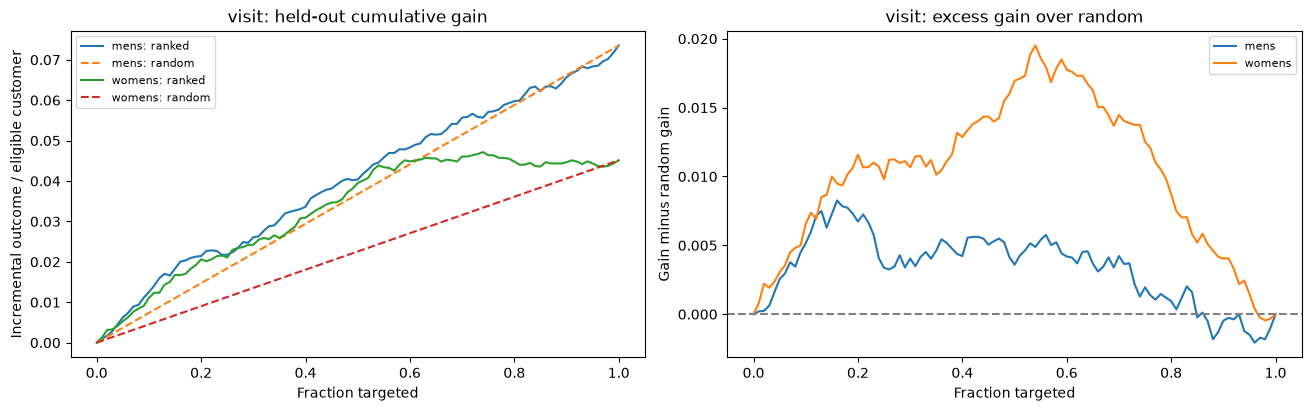

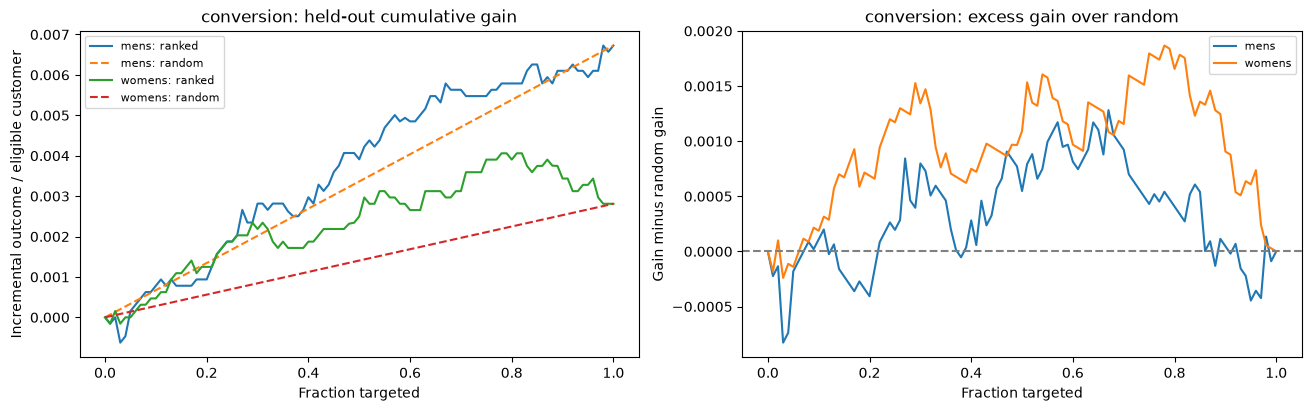

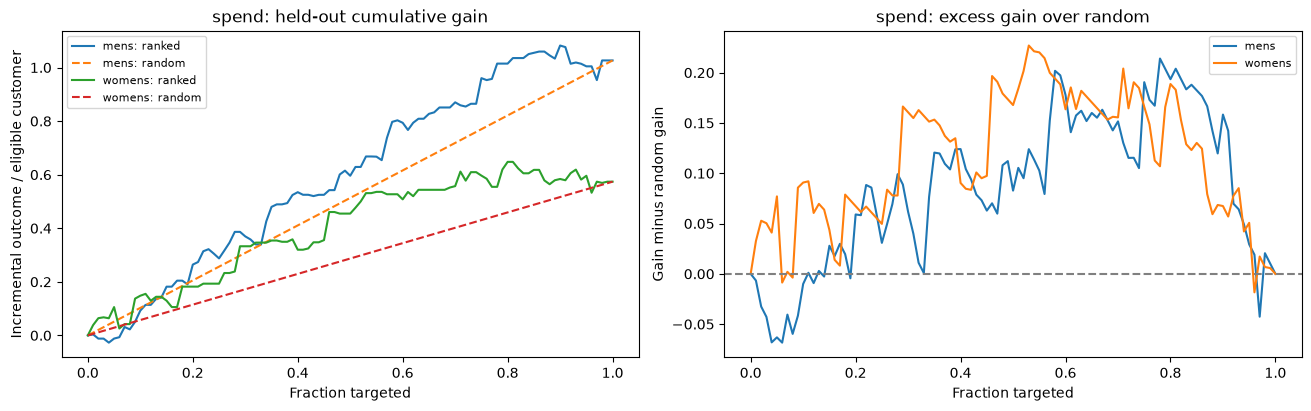

Saved six offline interactive charts and three notebook figures.


In [6]:
for outcome in OUTCOMES:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
    interactive_gain = go.Figure()
    interactive_excess = go.Figure()
    for name in ARMS.values():
        c = curves[outcome][name]
        x, gain, baseline = map(np.asarray, (c["fraction"], c["gain"], c["random"]))
        axes[0].plot(x, gain, label=f"{name}: ranked")
        axes[0].plot(x, baseline, linestyle="--", label=f"{name}: random")
        axes[1].plot(x, gain - baseline, label=name)
        interactive_gain.add_trace(go.Scatter(x=x, y=gain, name=f"{name}: ranked"))
        interactive_gain.add_trace(go.Scatter(x=x, y=baseline, name=f"{name}: random", line=dict(dash="dash")))
        interactive_excess.add_trace(go.Scatter(x=x, y=gain-baseline, name=name))
    axes[0].set(title=f"{outcome}: held-out cumulative gain", ylabel="Incremental outcome / eligible customer")
    axes[1].set(title=f"{outcome}: excess gain over random", ylabel="Gain minus random gain")
    axes[1].axhline(0, color="grey", linestyle="--")
    for ax in axes:
        ax.set_xlabel("Fraction targeted")
        ax.legend(fontsize=8)
    fig.savefig(OUTPUT / f"{outcome}_uplift.png", dpi=140)
    plt.show()
    for suffix, chart in [("gain", interactive_gain), ("qini", interactive_excess)]:
        chart.update_layout(title=f"{outcome}: held-out {suffix}",
                            xaxis_title="Fraction targeted", yaxis_title="Incremental outcome / eligible customer",
                            template="plotly_white")
        chart.write_html(OUTPUT / f"{outcome}_{suffix}.html", include_plotlyjs=True, auto_open=False)
print("Saved six offline interactive charts and three notebook figures.")

## 7. Save results and check consistency

The 64,000-row score table contains both training and held-out profiles. Use **only `split == 'test'`** for independent evaluation. In-sample scores are useful for demonstration but must not be presented as independent validation.

The model bundle stores the fitted encoder and exact input feature order. New customers must have the same baseline feature engineering as notebook 02. A model file alone is not a production deployment. Load joblib files only from trusted sources.

In [7]:
assert len(all_scores) == len(clean) and len(test_scores) == len(test)
for outcome in OUTCOMES:
    for name in ARMS.values():
        column = f"{outcome}_{name}"
        aligned = all_scores.set_index("customer_id").loc[test_scores.customer_id, column].to_numpy()
        assert np.allclose(aligned, test_scores[column]), "Score export alignment failed."
all_scores.to_csv(OUTPUT / "customer_scores.csv", index=False)
test_scores.to_csv(OUTPUT / "test_scores.csv", index=False)
averages.to_csv(OUTPUT / "average_effects.csv", index=False)
rankings.to_csv(OUTPUT / "ranking_evaluation.csv", index=False)
(OUTPUT / "uplift_curves.json").write_text(json.dumps(curves, indent=2, allow_nan=False))
joblib.dump({"encoder": encoder, "models": models, "raw_features": raw_features,
             "encoded_features": features, "treatments": {0: "No E-Mail", **ARMS}},
            MODEL_DIR / "double_ml_bundle.joblib", compress=3)
# Check that a saved model can reproduce predictions after loading.
reloaded = joblib.load(MODEL_DIR / "visit_forest.joblib")
assert np.allclose(reloaded.effect(X_test[:10], T0=0, T1=1).ravel(), test_scores.visit_mens.iloc[:10])
metadata = {"seed": SEED, "train_rows": len(train), "test_rows": len(test),
    "primary_outcome": "visit", "secondary_outcomes": ["conversion", "spend"],
    "cross_fitting_folds": 3, "causal_trees": 120, "nuisance_trees": 60,
    "bootstrap_repetitions": BOOTSTRAPS, "versions": versions,
    "raw_sha256": hashlib.sha256((ROOT / "data/raw/hillstrom.csv").read_bytes()).hexdigest(),
    "input_sha256": {p: hashlib.sha256((ROOT / p).read_bytes()).hexdigest() for p in needed},
    "meaning": "Estimated CATE for a profile, not observed individual treatment effect",
    "evaluation": "Fixed-model held-out pairwise IPW gain; tie-aware normalized area above random",
    "limits": "Exploratory intervals; no multiple-comparison adjustment or retraining uncertainty; no discount observations"}
(OUTPUT / "model_info.json").write_text(json.dumps(metadata, indent=2, allow_nan=False))
print("Saved scores, metrics, chart JSON, offline HTML, and models.")
print("Score alignment and saved-model reload checks passed.")
for row in ranking_rows:
    print(f"{row['outcome']} / {row['email']}: {row['finding']}; "
          f"Qini area {row['normalized_qini']:.5f}, 95% interval [{row['lower95']:.5f}, {row['upper95']:.5f}].")

Saved scores, metrics, chart JSON, offline HTML, and models.
Score alignment and saved-model reload checks passed.
visit / mens: Ranking advantage uncertain; Qini area 0.00336, 95% interval [-0.00077, 0.00703].
visit / womens: Positive ranking evidence (exploratory); Qini area 0.01028, 95% interval [0.00679, 0.01429].
conversion / mens: Ranking advantage uncertain; Qini area 0.00034, 95% interval [-0.00070, 0.00136].
conversion / womens: Positive ranking evidence (exploratory); Qini area 0.00097, 95% interval [0.00003, 0.00186].
spend / mens: Ranking advantage uncertain; Qini area 0.08562, 95% interval [-0.07967, 0.24244].
spend / womens: Ranking advantage uncertain; Qini area 0.11463, 95% interval [-0.04769, 0.27267].


## Explain this to your manager in one minute

“We used customers' shopping information from before the campaign. One Random Forest learned typical outcomes; another learned email assignment probabilities. EconML used cross-fitting and a causal forest to estimate how each email changes outcomes for similar customer profiles. We kept 30% of customers out of training and tested whether ranking them by estimated extra benefit beat random targeting. The charts and uncertainty table tell us where the evidence is strong and where it is inconclusive. These are email effects, not discount effects, and not certain personal outcomes.”

### What comes next
The mid-project notebook should perform DoWhy refutation and sensitivity checks. Such checks can reveal weaknesses but cannot prove there are no hidden confounders. The dashboard can load the saved scores and chart JSON; its filtering and load testing are separate work. Budget optimization belongs to Week 3.

### Sources and scope
- Supplied project screenshots and EconoCausal Project Guide: Week 2 EconML DML, Random Forest base estimators, customer-level scores, uplift/Qini visualization.
- [Original Hillstrom experiment description](https://blog.minethatdata.com/2008/03/minethatdata-e-mail-analytics-and-data.html): randomized email arms and two-week outcomes.
- [EconML CausalForestDML documentation](https://www.pywhy.org/EconML/_autosummary/econml.dml.CausalForestDML.html): cross-fitted nuisance models, categorical treatment, honest forests and effect intervals.

The requirement to demonstrate an advantage is treated as something to **evaluate honestly**, not a conclusion to force. Never tune repeatedly on the same held-out outcomes until a desirable curve appears.

## Verified run: what the results mean

The saved run used 44,800 training rows and 19,200 held-out rows, with 16 encoded baseline features. All seven code cells completed, and saved-model predictions matched their original predictions. An independent calculation using average score ranks reproduced all six Qini areas.

| Outcome and email | Normalized Qini area | Approximate 95% interval | Interpretation |
|---|---:|---:|---|
| Visit, men's | 0.00336 | −0.00077 to 0.00703 | Ranking advantage uncertain |
| Visit, women's | 0.01028 | 0.00679 to 0.01429 | Positive exploratory ranking evidence |
| Purchase, men's | 0.00034 | −0.00070 to 0.00136 | Ranking advantage uncertain |
| Purchase, women's | 0.00097 | 0.00003 to 0.00186 | Weak exploratory evidence; lower bound very near zero |
| Spend, men's | 0.08562 | −0.07967 to 0.24244 | Ranking advantage uncertain |
| Spend, women's | 0.11463 | −0.04769 to 0.27267 | Ranking advantage uncertain |

These areas have outcome-dependent units; do not compare spending areas directly with visit areas. Results may vary with software versions. The computed tables above are authoritative when you rerun this notebook.

**Two different questions:** the men's email increased average held-out visits by about 7.35 percentage points, but evidence that this model can rank its recipients better than random is inconclusive. An email can help on average without the model reliably discovering who benefits most. The women's email increased average held-out visits by about 4.46 percentage points and showed clearer ranking evidence for visits. A larger ranking area does not mean the women's email is always the better campaign.

The earlier EDA inspected the full dataset, so this is held-out model evaluation within an exploratory project, not a never-seen confirmatory experiment. The intervals are unadjusted across six checks; the women's purchase result is especially fragile. Stronger claims require a fresh validation sample or prospective experiment. No profit or discount conclusion follows from these results.
